[Megnyitás a Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/biztonsagkritikus-rendszerek/blob/main/gyakorlat/notebookok/02_kockazat_irpa_fn.ipynb) · *Biztonságkritikus rendszerek – gyakorlati útmutató* · © 2026 Abonyi János, Pannon Egyetem · kód: MIT, szöveg: CC BY-NC-SA 4.0

# 2. gyakorlat – egyéni és társadalmi kockázat

Ez a notebook a könyv 3. fejezetének két kvantitatív eszközét számolja végig: az **egyéni kockázatot** (IRPA) egy kezelőre, és a **társadalmi kockázatot** egy kis létesítmény **F–N görbéjével**.

**Tanulási eredmények:** a notebook végére képes leszel IRPA-t számolni forgatókönyvekből, F–N görbét szerkeszteni és kritériumvonallal összevetni, valamint megállapítani, melyik forgatókönyv a kockázat domináns forrása.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
PE = {"kek": "#285780", "sotet": "#1B3A57", "kiemel": "#E07B39", "zold": "#3E8E63", "piros": "#B83A3A", "lila": "#7A5C99", "szurke": "#6B7280"}
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.grid": True, "grid.color": "#e6e9ee", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=list(PE.values())), "axes.formatter.use_locale": False})
def hu(x, sig=3):
    """Szám magyar formátumban (tizedesvessző, normálalak)."""
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    if -2 <= e < 5: return f"{x:.{max(0, sig-1-e)}f}".replace(".", ",")
    return f"{x/10**e:.{sig-1}f}".replace(".", ",") + f"·10^{e}"


## 1. Egyéni kockázat

$\text{IRPA} = \sum_i F_i \, P_{\mathrm{h},i} \, P_{\mathrm{j},i}$, ahol $F_i$ a forgatókönyv gyakorisága, $P_{\mathrm{h},i}$ a halálos kimenetel, $P_{\mathrm{j},i}$ a jelenlét valószínűsége. Az adatok a könyv 3. fejezetének példájából valók (a reaktorfelhasadás gyakorisága a 11. fejezet eseményfájából).

In [2]:
forgatokonyvek = [  # név, F [1/év], P_halálos, P_jelenlét
    ("reaktor felhasadása megfutó reakció miatt", 6.8e-6, 0.9, 0.25),
    ("mérgező gőz kis szivárgása",                 1e-2,  1e-4, 0.25),
    ("tűz a betöltőnyílásnál",                     1e-4,  0.1, 0.25),
]
irpa = 0
for nev, F, Ph, Pj in forgatokonyvek:
    h = F * Ph * Pj; irpa += h
    print(f"{nev:45s} {hu(h)} /év")
print(f"{'összesen':45s} {hu(irpa)} /év")
for nev, F, Ph, Pj in forgatokonyvek:
    print(f"  {nev}: {100*F*Ph*Pj/irpa:.0f} %")

reaktor felhasadása megfutó reakció miatt     1,53·10^-6 /év
mérgező gőz kis szivárgása                    2,50·10^-7 /év
tűz a betöltőnyílásnál                        2,50·10^-6 /év
összesen                                      4,28·10^-6 /év
  reaktor felhasadása megfutó reakció miatt: 36 %
  mérgező gőz kis szivárgása: 6 %
  tűz a betöltőnyílásnál: 58 %


**Értelmezés.** Az eredmény ($4{,}3\cdot10^{-6}$/év) a brit HSE-kritériumok szerint a tolerálható tartomány alsó részébe esik, ezért ALARP-igazolás kell. A legnagyobb hozzájárulás a tűzé, nem a látványosabb reaktorfelhasadásé.

**1. feladat.** Mennyivel csökken az IRPA, ha zárt betöltéssel a tűz gyakoriságát tizedére csökkentjük? Melyik forgatókönyv lesz ezután a domináns?

In [3]:
# 1. feladat – írd ide a megoldást


## 2. F–N görbe

Az F–N görbe azt mutatja, mekkora gyakorisággal fordul elő $N$ vagy több áldozatot követelő baleset. A kritériumvonal $F = C/N^{a}$ alakú; itt a könyv ábrájának megfelelően $C = 10^{-3}$, $a = 2$ (kockázatkerülő), az elhanyagolható szint $10^{-5}/N^2$. A létesítmény forgatókönyvei (szemléltető adatok):

F(N ≥    1) = 2,00·10^-5 /év   kritérium: 1,00·10^-3   megfelel
F(N ≥    3) = 6,00·10^-6 /év   kritérium: 1,11·10^-4   megfelel
F(N ≥   10) = 1,20·10^-6 /év   kritérium: 1,00·10^-5   megfelel
F(N ≥   40) = 2,00·10^-7 /év   kritérium: 6,25·10^-7   megfelel
F(N ≥  120) = 1,00·10^-8 /év   kritérium: 6,94·10^-8   megfelel


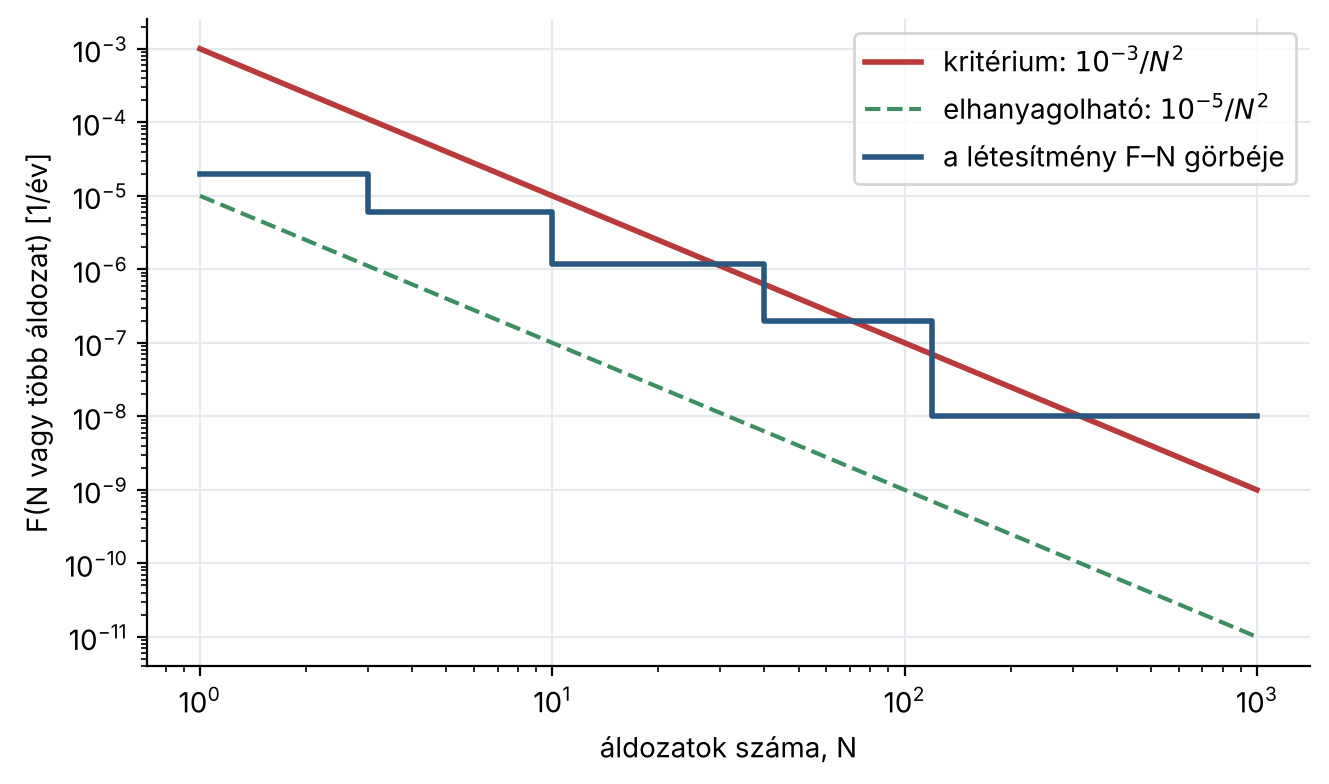

In [4]:
esemenyek = np.array([  # áldozatok száma, gyakoriság [1/év]
    [1, 1.4e-5], [3, 4.8e-6], [10, 1.0e-6], [40, 1.9e-7], [120, 1.0e-8]])
N = np.sort(np.unique(esemenyek[:, 0]))
F_N = np.array([esemenyek[esemenyek[:, 0] >= n, 1].sum() for n in N])
for n, f in zip(N, F_N):
    print(f"F(N ≥ {int(n):4d}) = {hu(f)} /év   kritérium: {hu(1e-3/n**2)}   {'megfelel' if f <= 1e-3/n**2 else 'NEM felel meg'}")
fig, ax = plt.subplots()
xs = np.logspace(0, 3, 50)
ax.loglog(xs, 1e-3/xs**2, color=PE["piros"], lw=2, label="kritérium: $10^{-3}/N^2$")
ax.loglog(xs, 1e-5/xs**2, color=PE["zold"], ls="--", label="elhanyagolható: $10^{-5}/N^2$")
ax.step(np.append(N, 1000), np.append(F_N, F_N[-1]), where="post", color=PE["kek"], lw=2, label="a létesítmény F–N görbéje")
ax.set_xlabel("áldozatok száma, N"); ax.set_ylabel("F(N vagy több áldozat) [1/év]"); ax.legend(); plt.show()

**2. feladat.** Egy új forgatókönyv (például egy gáztartály felrobbanása) $5\cdot10^{-8}$/év gyakorisággal 200 áldozatot követelhet. Add hozzá, és vizsgáld meg, átlépi-e a görbe a kritériumvonalat! Mit jelent a kockázatkerülés ($a = 2$) ebben az esetben?

**3. feladat.** Hasonlítsd össze az $a = 1$ (kockázatsemleges) és az $a = 2$ kritériumot: mely forgatókönyvekre szigorúbb az egyik, és melyekre a másik?

## Mintapromptok

- *„Magyarázd el, miért használnak egyes országok kockázatkerülő (a = 2) F–N kritériumot! Milyen etikai és gyakorlati érvek szólnak mellette és ellene? Hivatkozz konkrét szabályozásokra, és jelöld, ha bizonytalan vagy.”*
- *„Ellenőrizd a fenti Python-kód logikáját: helyesen számolja-e a kumulált F(N ≥ n) gyakoriságot? Ne írd át a kódot, csak a hibákat jelezd.”*